# Experiment 193 · Replay and temporal gradient correlation

**Complete** · Reconstruction, gradient and probe results saved · ETA 0h 00m 00s

The two stream orders share the original A initialization and the same frames in every subsequent 768-arrival window. The window shuffle changes frame order within each window and preserves the A–B–A–B switch times. Six model seeds and two paired mask draws reuse this fixed stream pair. All policies take one optimizer step per arrival.

Broad replay samples uniformly from causal history. Stratified replay draws once from each of four causal age bands in every four replay slots, with a randomized band order. Recent replay draws uniformly with replacement from up to 768 previous arrivals in the active regime. The no-replay arm measures how much the stream shuffle itself helps, and the broad 50% arm uses twice the replay of the 25% arms. The original-order no-replay and broad trajectories come from Experiments 190–191.

Primary outcomes are time-averaged current and historical test-bank MSE after the initial regime. Gains use matched seed and mask pairs. The intervals are 95% paired Student t intervals over the six seed means. External scene, weather, lighting and pedestrian balanced accuracies are evaluated at the end.

Completed trajectories · 120. Gradient windows · 72. External probe runs · 120.

## Gradient and embedding diagnostics

Gradients are computed without an optimizer update using the same frozen checkpoint across policies and orders, with MAE masks paired by arrival. Each window measures selected training images at a switch or 3,072 arrivals later. The no-replay rows measure incoming temporal redundancy.

| Order | Policy | Windows | Grad cos lag 1 | Grad cos lag 2 | Grad cos lag 4 | Grad cos lag 8 | Embed cos lag 1 | RGB lag-1 absolute difference |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | clip order | no replay | 72 | 0.7795 | 0.7690 | 0.7366 | 0.6895 | 0.9998 | 0.0104 | 
 | clip order | broad 25% | 72 | 0.4525 | 0.4368 | 0.5839 | 0.5439 | 0.7837 | 0.1556 | 
 | clip order | broad 50% | 72 | 0.1133 | 0.4422 | 0.4316 | 0.3996 | 0.5602 | 0.3107 | 
 | clip order | stratified 25% | 72 | 0.4777 | 0.4668 | 0.5876 | 0.5544 | 0.7672 | 0.1573 | 
 | clip order | recent 25% | 72 | 0.6532 | 0.6404 | 0.6835 | 0.6449 | 0.9947 | 0.0418 | 
 | window shuffle | no replay | 72 | 0.3835 | 0.3817 | 0.3765 | 0.3951 | 0.9561 | 0.1072 | 
 | window shuffle | broad 25% | 72 | 0.2427 | 0.2589 | 0.3185 | 0.3411 | 0.7798 | 0.2029 | 
 | window shuffle | broad 50% | 72 | 0.1004 | 0.2760 | 0.2516 | 0.2707 | 0.5879 | 0.3085 | 
 | window shuffle | stratified 25% | 72 | 0.2639 | 0.2761 | 0.3227 | 0.3492 | 0.7619 | 0.2068 | 
 | window shuffle | recent 25% | 72 | 0.3715 | 0.3962 | 0.3869 | 0.4047 | 0.9583 | 0.1110 | 

## Time-averaged reconstruction

| Order | Policy | Matched pairs | Current MSE | Historical MSE |
| --- | --- | --- | --- | --- |
 | clip order | no replay | 12 | 0.92261 | 1.24645 | 
 | clip order | broad 25% | 12 | 0.90297 | 0.87000 | 
 | clip order | broad 50% | 12 | 0.88293 | 0.85048 | 
 | clip order | stratified 25% | 12 | 0.90360 | 0.86914 | 
 | clip order | recent 25% | 12 | 0.90045 | 1.15376 | 
 | window shuffle | no replay | 12 | 0.87427 | 1.04666 | 
 | window shuffle | broad 25% | 12 | 0.86710 | 0.85378 | 
 | window shuffle | broad 50% | 12 | 0.86485 | 0.84399 | 
 | window shuffle | stratified 25% | 12 | 0.86754 | 0.85395 | 
 | window shuffle | recent 25% | 12 | 0.87019 | 1.03959 | 

The descriptive Pareto sets contain policies for which no other policy in the corresponding comparison improves one MSE while matching or improving the other.

| Order | All replay rates | Equal 25% replay |
| --- | --- | --- |
 | clip order | broad 50% | broad 25%, stratified 25%, recent 25% | 
 | window shuffle | broad 50% | broad 25% | 

| Order | Policy | Reference | Current MSE reduction [95% CI] | Historical MSE reduction [95% CI] |
| --- | --- | --- | --- | --- |
 | clip order | broad 25% | no replay | +0.01964 [+0.01671, +0.02258] | +0.37645 [+0.36702, +0.38588] | 
 | clip order | broad 50% | no replay | +0.03968 [+0.03696, +0.04239] | +0.39597 [+0.38646, +0.40547] | 
 | clip order | broad 50% | broad 25% | +0.02003 [+0.01811, +0.02196] | +0.01952 [+0.01708, +0.02195] | 
 | clip order | stratified 25% | broad 25% | -0.00063 [-0.00178, +0.00053] | +0.00086 [+0.00011, +0.00160] | 
 | clip order | recent 25% | broad 25% | +0.00252 [-0.00024, +0.00528] | -0.28376 [-0.32482, -0.24271] | 
 | clip order | recent 25% | no replay | +0.02216 [+0.02100, +0.02332] | +0.09269 [+0.05517, +0.13020] | 
 | window shuffle | broad 25% | no replay | +0.00718 [+0.00439, +0.00997] | +0.19289 [+0.18037, +0.20541] | 
 | window shuffle | broad 50% | no replay | +0.00942 [+0.00644, +0.01241] | +0.20267 [+0.18872, +0.21663] | 
 | window shuffle | broad 50% | broad 25% | +0.00225 [+0.00191, +0.00259] | +0.00979 [+0.00821, +0.01136] | 
 | window shuffle | stratified 25% | broad 25% | -0.00044 [-0.00143, +0.00055] | -0.00018 [-0.00154, +0.00119] | 
 | window shuffle | recent 25% | broad 25% | -0.00309 [-0.00624, +0.00006] | -0.18582 [-0.20025, -0.17138] | 
 | window shuffle | recent 25% | no replay | +0.00409 [+0.00325, +0.00493] | +0.00707 [-0.00463, +0.01877] | 

## Does the benefit change with stream order?

Positive values indicate a larger gain with clip order. Estimates subtract the within-order effect of the window shuffle from the within-order effect of the clip stream.

| Policy | Reference | Pairs | Current benefit difference [95% CI] | Historical benefit difference [95% CI] |
| --- | --- | --- | --- | --- |
 | broad 25% | no replay | 12 | +0.01246 [+0.00985, +0.01508] | +0.18356 [+0.17358, +0.19354] | 
 | broad 50% | no replay | 12 | +0.03025 [+0.02816, +0.03234] | +0.19329 [+0.18025, +0.20633] | 
 | broad 50% | broad 25% | 12 | +0.01779 [+0.01582, +0.01976] | +0.00973 [+0.00613, +0.01333] | 
 | stratified 25% | broad 25% | 12 | -0.00019 [-0.00150, +0.00112] | +0.00103 [-0.00096, +0.00303] | 
 | recent 25% | broad 25% | 12 | +0.00561 [+0.00223, +0.00898] | -0.09795 [-0.12813, -0.06776] | 
 | recent 25% | no replay | 12 | +0.01807 [+0.01651, +0.01963] | +0.08561 [+0.05172, +0.11951] | 

## External frozen probes

| Order | Policy | Runs | Scene | Weather | Lighting | Pedestrian |
| --- | --- | --- | --- | --- | --- | --- |
 | clip order | no replay | 12 | 42.48% | 45.19% | 96.45% | 59.82% | 
 | clip order | broad 25% | 12 | 43.90% | 44.19% | 95.36% | 58.83% | 
 | clip order | broad 50% | 12 | 43.89% | 44.88% | 96.30% | 58.80% | 
 | clip order | stratified 25% | 12 | 43.52% | 43.78% | 96.22% | 58.88% | 
 | clip order | recent 25% | 12 | 42.31% | 44.80% | 95.67% | 58.49% | 
 | window shuffle | no replay | 12 | 41.74% | 45.73% | 95.04% | 58.33% | 
 | window shuffle | broad 25% | 12 | 42.45% | 45.22% | 96.62% | 58.28% | 
 | window shuffle | broad 50% | 12 | 42.87% | 46.32% | 96.14% | 58.52% | 
 | window shuffle | stratified 25% | 12 | 42.96% | 45.86% | 96.38% | 58.75% | 
 | window shuffle | recent 25% | 12 | 41.71% | 46.12% | 95.52% | 57.60% | 



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-replay-decorrelation')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


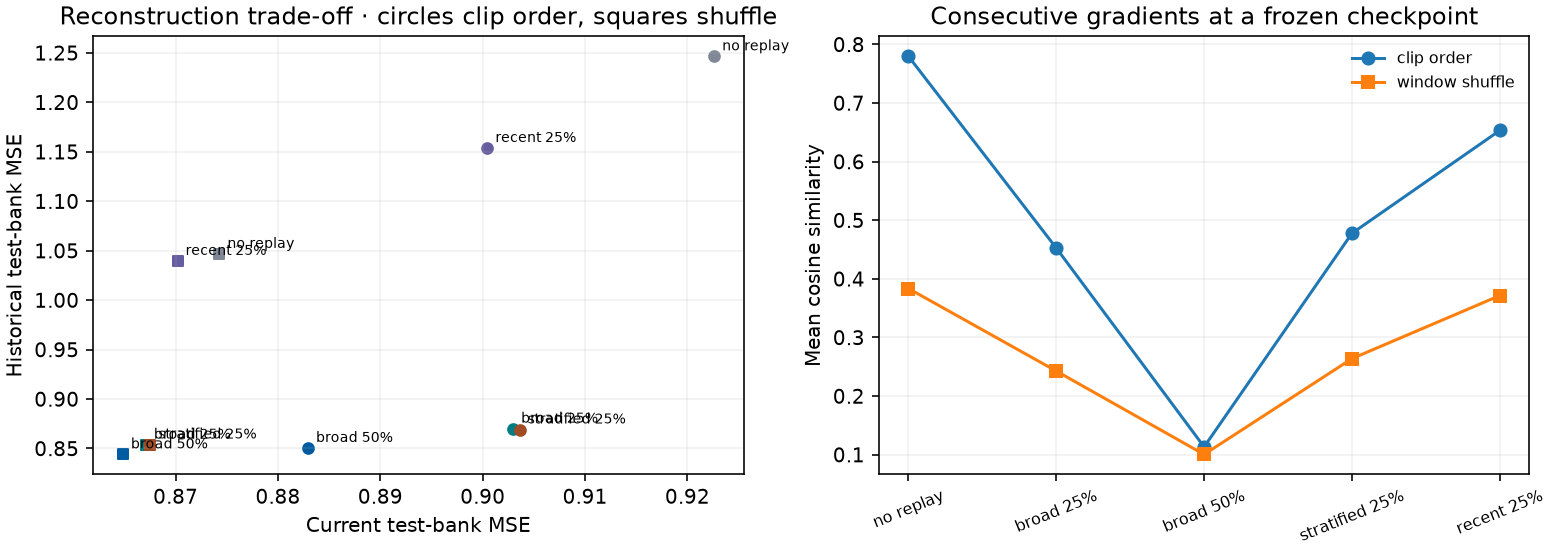